# HanuAi Task 1: BestBuy Canada Review Scraper + Sentiment Analysis

**Before you run:** open a BestBuy.ca product page that has **50+ reviews**, copy its URL into `PRODUCT_URL` below, and run the cells top to bottom on your own computer (needs internet).

What this notebook does
1. Opens the product page with Playwright (real browser, so the JavaScript reviews load)
2. Clicks "Show more" until all reviews are loaded, for each sort order (Most helpful, Newest, Highest rating, Lowest rating)
3. Parses each review with BeautifulSoup and collects: primary key, title, body, date (`YYYY-MM-DD`), star rating, source platform, reviewer name
4. Cleans the text, scores sentiment (Positive / Negative / Neutral) and adds aspect tags like `Good Design & Quality (Pos)`
5. Saves the dataset to CSV and Excel

> **If BestBuy shows "Access Denied":** the site can block automated browsers. Do not keep retrying. Fill the Excel template `manual_reviews_template.xlsx` with 50+ real reviews you copy from the product page, save it as `manual_reviews.xlsx` in this folder, and run section 3 again. The notebook then skips scraping and runs everything else on your data.
>
> **Important:** I wrote the page selectors from how BestBuy.ca pages are usually built, but I could not open the live site from my workspace. So the first time you run it, check the "Selector check" cell. If it finds 0 reviews, open the page, right click a review, Inspect, and update the selectors in `SELECTORS`. Everything else (sorting, clicking, retries, parsing, sentiment) does not depend on that.

In [1]:
# one-time setup (run in a terminal, not in the notebook):
#   pip install playwright beautifulsoup4 lxml pandas vaderSentiment openpyxl
#   playwright install chromium

In [2]:
import re, time, random, hashlib, uuid, json
from datetime import datetime
import pandas as pd
from bs4 import BeautifulSoup
from playwright.sync_api import sync_playwright, TimeoutError as PWTimeout

# ----------------------------- settings -----------------------------
PRODUCT_URL = 'https://www.bestbuy.ca/en-ca/product/REPLACE-ME'   # <- put your product URL here
SOURCE_PLATFORM = 'BestBuy Canada'
SORT_OPTIONS = ['Most Helpful', 'Newest', 'Highest Rating', 'Lowest Rating']   # label text shown in the sort dropdown
HEADLESS = False          # False = you can watch the browser. True = no window
MAX_SHOW_MORE_CLICKS = 60
MIN_DELAY, MAX_DELAY = 1.2, 3.0     # polite random pause between actions (seconds)
PROXY = None              # e.g. {'server': 'http://host:port', 'username': '...', 'password': '...'}  (optional)

# CSS selectors. several fallbacks per item, first one that matches is used.
# If you get 0 reviews, inspect the page and fix these.
SELECTORS = {
    'review_card':  ['[data-automation="review"]', '[class*="reviewItem"]', '[class*="review-item"]', 'li[class*="review"]', 'div[class*="review"][itemprop="review"]'],
    'title':        ['[data-automation="review-title"]', '[class*="reviewTitle"]', '[class*="review-title"]', 'h3', 'h4'],
    'body':         ['[data-automation="review-text"]', '[class*="reviewText"]', '[class*="review-text"]', '[class*="reviewContent"]', 'p'],
    'date':         ['[data-automation="review-date"]', 'time', '[class*="reviewDate"]', '[class*="review-date"]', '[itemprop="datePublished"]'],
    'author':       ['[data-automation="review-author"]', '[class*="reviewAuthor"]', '[class*="review-author"]', '[class*="reviewer"]', '[itemprop="author"]'],
    'rating':       ['[itemprop="ratingValue"]', '[aria-label*="out of 5"]', '[class*="rating"][aria-label]', '[class*="stars"][aria-label]', '[class*="rating"]'],
    'show_more':    ['button:has-text("Show more")', 'button:has-text("Show More")', 'button:has-text("Load more")', 'a:has-text("Show more")'],
    'sort_select':  ['select[aria-label*="Sort"]', 'select[class*="sort"]', 'select'],
}

USER_AGENTS = [
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36',
    'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/123.0.0.0 Safari/537.36',
    'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36',
]

## 1. Helpers: polite pauses, retries with backoff, parsing

In [3]:
def pause(a=MIN_DELAY, b=MAX_DELAY):
    time.sleep(random.uniform(a, b))

def with_retry(fn, tries=4, base=2.0, what='action'):
    """Run fn(). On failure wait 2s, 4s, 8s... (plus a little random jitter) and try again."""
    for i in range(1, tries + 1):
        try:
            return fn()
        except Exception as e:
            if i == tries:
                print(f'  [{what}] failed after {tries} tries: {type(e).__name__}')
                raise
            wait = base ** i + random.uniform(0, 1)
            print(f'  [{what}] try {i} failed ({type(e).__name__}), waiting {wait:.1f}s')
            time.sleep(wait)

def first_text(node, selector_list):
    for sel in selector_list:
        el = node.select_one(sel)
        if el:
            txt = el.get('aria-label') or el.get('content') or el.get('datetime') or el.get_text(' ', strip=True)
            if txt:
                return txt.strip()
    return ''

def parse_rating(raw):
    """'4 out of 5', '4.0', 'Rated 5 stars' -> 4.0 / 5.0. returns None if no number found"""
    m = re.search(r'(\d(?:\.\d)?)', raw or '')
    if not m: return None
    v = float(m.group(1))
    return v if 0 <= v <= 5 else None

def parse_date(raw):
    """returns YYYY-MM-DD or '' . handles ISO dates, 'March 3, 2024', 'Mar 3, 2024', '3 March 2024'"""
    raw = (raw or '').strip()
    if not raw: return ''
    m = re.search(r'\d{4}-\d{2}-\d{2}', raw)
    if m: return m.group(0)
    for fmt in ('%B %d, %Y', '%b %d, %Y', '%d %B %Y', '%d %b %Y', '%Y/%m/%d', '%m/%d/%Y'):
        try:
            return datetime.strptime(re.sub(r'\s+', ' ', raw.replace('Reviewed on', '').strip()), fmt).strftime('%Y-%m-%d')
        except ValueError:
            continue
    return ''   # relative dates like "3 days ago" are handled below if needed

def parse_reviews(html):
    soup = BeautifulSoup(html, 'lxml')
    cards = []
    for sel in SELECTORS['review_card']:
        cards = soup.select(sel)
        if cards: break
    rows = []
    for c in cards:
        title = first_text(c, SELECTORS['title'])
        body = first_text(c, SELECTORS['body'])
        if body == title: body = ''          # same element matched twice
        rows.append({
            'Review Title': title,
            'Review Body': body,
            'Date': parse_date(first_text(c, SELECTORS['date'])),
            'Star Rating': parse_rating(first_text(c, SELECTORS['rating'])),
            'Source Platform': SOURCE_PLATFORM,
            'Reviewer Name': first_text(c, SELECTORS['author']).replace('By ', '').strip() or 'Anonymous',
        })
    return rows

def make_key(r):
    """stable unique id from the review content, so the same review scraped under two sort orders gets the same id"""
    raw = '|'.join([r['Reviewer Name'], r['Date'], r['Review Title'], r['Review Body'][:200]])
    return 'BBC-' + hashlib.md5(raw.encode('utf-8')).hexdigest()[:12]

## 2. Scraper
Anti-blocking measures used here (explained in the report):
- real browser (Playwright) so JavaScript runs, with a normal desktop user agent, viewport, `en-CA` locale and Toronto timezone
- random human-like pauses between clicks and scrolls
- retries with exponential backoff on timeouts and connection errors
- optional proxy setting

In [4]:
def click_first(page, selector_list, timeout=2500):
    for sel in selector_list:
        loc = page.locator(sel).first
        try:
            if loc.count() and loc.is_visible():
                loc.scroll_into_view_if_needed(timeout=timeout)
                loc.click(timeout=timeout)
                return True
        except PWTimeout:
            continue
        except Exception:
            continue
    return False

def apply_sort(page, label):
    """pick a sort order from the dropdown (native <select>) - falls back to clicking a button/option with that text"""
    for sel in SELECTORS['sort_select']:
        loc = page.locator(sel).first
        try:
            if loc.count():
                loc.select_option(label=label, timeout=2500)
                return True
        except Exception:
            pass
    try:
        page.get_by_text(label, exact=False).first.click(timeout=2500)
        return True
    except Exception:
        print(f'  could not apply sort "{label}" - continuing with the current order')
        return False

def load_all_reviews(page):
    """keep clicking 'Show more' until it disappears or the number of cards stops growing"""
    last, stale = -1, 0
    for i in range(MAX_SHOW_MORE_CLICKS):
        n = 0
        for sel in SELECTORS['review_card']:
            n = page.locator(sel).count()
            if n: break
        if n == last:
            stale += 1
            if stale >= 2: break
        else:
            stale = 0
        last = n
        page.mouse.wheel(0, 2500)
        pause(0.6, 1.4)
        if not click_first(page, SELECTORS['show_more']):
            break
        pause()
    return last

def scrape(url=PRODUCT_URL):
    all_rows = []
    with sync_playwright() as p:
        try:
            browser = p.chromium.launch(channel='chrome', headless=HEADLESS, proxy=PROXY)   # your installed Google Chrome
        except Exception:
            browser = p.chromium.launch(headless=HEADLESS, proxy=PROXY)                    # fallback: bundled Chromium
        ctx = browser.new_context(user_agent=random.choice(USER_AGENTS), viewport={'width': 1366, 'height': 850},
                                  locale='en-CA', timezone_id='America/Toronto',
                                  extra_http_headers={'Accept-Language': 'en-CA,en;q=0.9'})
        page = ctx.new_page()

        with_retry(lambda: page.goto(url, wait_until='domcontentloaded', timeout=60000), what='open product page')
        pause(2, 4)
        title = page.title().lower()
        if 'denied' in title or 'blocked' in title or 'captcha' in title:
            browser.close()
            raise RuntimeError('BestBuy blocked this browser (page title: "%s"). Do not keep retrying. '
                               'Use the manual option: put reviews in manual_reviews.xlsx (see the notebook intro).' % page.title())
        # accept cookie banner if there is one
        click_first(page, ['button:has-text("Accept")', 'button:has-text("Got it")', '#onetrust-accept-btn-handler'])
        # scroll down to the reviews section so it renders
        for _ in range(4):
            page.mouse.wheel(0, 1800); pause(0.5, 1.0)
        click_first(page, ['a:has-text("Reviews")', 'button:has-text("Reviews")', '[href*="reviews"]'])
        pause()

        for sort_label in SORT_OPTIONS:
            print('sort:', sort_label)
            apply_sort(page, sort_label)
            pause(1.5, 3)
            n = with_retry(lambda: load_all_reviews(page), what='load reviews')
            rows = parse_reviews(page.content())
            print(f'  cards on page: {n}, parsed: {len(rows)}')
            for r in rows:
                r['Sort Seen In'] = sort_label
            all_rows += rows
        browser.close()
    return all_rows

In [5]:
# ---- Selector check (run this first, on its own) ----
# opens the page, grabs the HTML once and tells you how many review cards the selectors find.
def selector_check(url=PRODUCT_URL):
    with sync_playwright() as p:
        b = p.chromium.launch(headless=False)
        pg = b.new_context(user_agent=USER_AGENTS[0], locale='en-CA').new_page()
        pg.goto(url, wait_until='domcontentloaded', timeout=60000)
        for _ in range(6):
            pg.mouse.wheel(0, 1800); time.sleep(1)
        html = pg.content(); b.close()
    rows = parse_reviews(html)
    print('reviews found on first load:', len(rows))
    print(pd.DataFrame(rows).head())
    open('page_snapshot.html', 'w', encoding='utf-8').write(html)    # open this file to find the right selectors
# selector_check()

## 3. Run the scraper and build the raw dataset

In [6]:
import os, sys, asyncio, warnings, concurrent.futures

def run_scrape():
    # Jupyter on Windows cannot start the browser in its default loop mode, so use the Proactor loop in a worker thread
    if sys.platform == 'win32':
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            asyncio.set_event_loop_policy(asyncio.WindowsProactorEventLoopPolicy())
    return scrape()

MANUAL_FILE = 'manual_reviews.xlsx'
if os.path.exists(MANUAL_FILE):
    # reviews typed / copied by hand into the Excel template -> use these instead of scraping
    print('Using', MANUAL_FILE, '(manual data)')
    df = pd.read_excel(MANUAL_FILE).dropna(how='all')
    df['Review Title'] = df['Review Title'].fillna('').astype(str)
    df['Review Body'] = df['Review Body'].fillna('').astype(str)
    df['Reviewer Name'] = df['Reviewer Name'].fillna('Anonymous').astype(str)
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce').dt.strftime('%Y-%m-%d').fillna('')
    df['Star Rating'] = pd.to_numeric(df['Star Rating'], errors='coerce')
    df['Source Platform'] = SOURCE_PLATFORM
else:
    with concurrent.futures.ThreadPoolExecutor(max_workers=1) as ex:
        raw_rows = ex.submit(run_scrape).result()
    df = pd.DataFrame(raw_rows)
    print(len(df), 'rows scraped (before removing duplicates across sort orders)')
    if df.empty:
        raise RuntimeError('0 reviews found. The page may have blocked the browser or the selectors need fixing. '
                           'Fallback: fill manual_reviews.xlsx and run this cell again.')
    df = df.drop(columns=['Sort Seen In'])

# same review can appear under several sorts -> keep one
df['Primary Key'] = df.apply(make_key, axis=1)
df = df.drop_duplicates('Primary Key').reset_index(drop=True)
df = df[['Primary Key', 'Review Title', 'Review Body', 'Date', 'Star Rating', 'Source Platform', 'Reviewer Name']]
print(len(df), 'unique reviews')
assert len(df) >= 50, 'task needs at least 50 reviews - check the product / selectors / manual file'
df.head()

Using manual_reviews.xlsx (manual data)
60 unique reviews


,Primary Key,Review Title,Review Body,Date,Star Rating,Source Platform,Reviewer Name
0,BBC-67159652847a,Great features !!,I am so happy with this sony headphones!! The ...,2022-10-13,NaN,BestBuy Canada,Radwa
1,BBC-c3ee510f2f4b,Top of the line!,The WH-1000XM5 wireless noise canceling headph...,2022-10-21,5.0,BestBuy Canada,Arlette22
2,BBC-6a4acbc77990,WH-1000XM5 WIRELESS HEADPHONES ROCK,"I wear headphones everyday for my job , and fo...",2022-10-27,5.0,BestBuy Canada,Justme45
3,BBC-c085e19da2ae,WH-1000XM5 Vibing,I bought this headphone today and the unboxing...,2025-03-04,5.0,BestBuy Canada,Adeeric
4,BBC-95b060df980e,Blocks Noise & Plays Favorite Music,I absolutely love the Sony noise canceling hea...,2022-10-12,5.0,BestBuy Canada,Cher12


In [7]:
# quick quality checks on the scraped fields
print(df.isna().sum())
print('empty body :', (df['Review Body'].str.strip() == '').sum())
print('bad dates  :', (~df['Date'].str.match(r'^\d{4}-\d{2}-\d{2}$')).sum())
print(df['Star Rating'].value_counts().sort_index())

Primary Key        0
Review Title       0
Review Body        0
Date               0
Star Rating        2
Source Platform    0
Reviewer Name      0
dtype: int64
empty body : 0
bad dates  : 0
Star Rating
1.0     3
2.0     3
4.0     6
5.0    46
Name: count, dtype: int64


## 4. Sentiment analysis and aspect tags

**Cleaning:** join title + body, fix HTML entities and odd characters, collapse spaces.

**Sentiment model:** VADER (a lexicon + rules model made for review style text, runs offline and is easy to explain). It scores every sentence and I average them (`Text Score`). On long reviews VADER leans positive and misses reviews that praise one thing and then complain about another, so the final label blends the text score 50/50 with the star rating (`Sentiment`). The text-only label is kept too (`Sentiment (text only)`) and is checked against the stars below. Labels: score `>= 0.1` Positive, `<= -0.1` Negative, otherwise Neutral. An optional Hugging Face transformer is included below if you want to compare.

**Aspect tags:** each review is split into sentences. When a sentence mentions an aspect (design, battery, price...) I score that sentence and produce a tag such as `Good Design & Quality (Pos)`. If nothing specific is mentioned, the tag is `Satisfactory & Recommended (Pos)` or the negative / neutral equivalent, based on the overall sentiment.

In [8]:
import html as htmllib
import numpy as np
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()

def clean_text(title, body):
    t = f'{title}. {body}' if title and body else (title or body or '')
    t = htmllib.unescape(t)
    t = t.replace('’', "'").replace('“', '"').replace('”', '"')
    t = re.sub(r'<[^>]+>', ' ', t)
    t = re.sub(r'http\S+', ' ', t)
    t = re.sub(r'[^\w\s\.,!?\'"%$/\-+&:;()]', ' ', t)      # drop emoji and odd symbols
    return re.sub(r'\s+', ' ', t).strip()

def polarity(score, t=0.05):
    return 'Positive' if score >= t else ('Negative' if score <= -t else 'Neutral')

def sentence_avg(text):
    # VADER on a long review saturates towards "positive", so I also average the score sentence by sentence
    sents = [x.strip() for x in re.split(r'(?<=[.!?])\s+', text) if len(x.strip()) > 3]
    return float(np.mean([vader.polarity_scores(x)['compound'] for x in sents])) if sents else 0.0

df['Clean Text'] = [clean_text(t, b) for t, b in zip(df['Review Title'], df['Review Body'])]
df['Text Score (whole review)'] = df['Clean Text'].map(lambda t: vader.polarity_scores(t)['compound'])
df['Text Score'] = df['Clean Text'].map(sentence_avg)                     # average of sentence scores
df['Sentiment (text only)'] = df['Text Score'].map(lambda x: polarity(x, 0.1))

# Final label = text score blended 50/50 with the star rating (rescaled to -1..+1).
# If a review has no star rating, the text score is used alone.
star_score = (df['Star Rating'] - 3) / 2
df['Sentiment Score'] = np.where(star_score.notna(), 0.5 * df['Text Score'] + 0.5 * star_score, df['Text Score'])
df['Sentiment'] = df['Sentiment Score'].map(lambda x: polarity(x, 0.1))
df['Sentiment'].value_counts()

Sentiment
Positive    53
Negative     6
Neutral      1
Name: count, dtype: int64

In [9]:
# aspects. edit / extend the keyword lists to fit your product (these are generic for electronics)
ASPECTS = {
    'Design & Quality':      r'design|look|looks|build|quality|sturdy|durable|premium|material|finish|solid|sleek|feel',
    'Performance':           r'perform|fast|slow|speed|lag|smooth|responsive|power|works? (great|well|perfect)|stopped working',
    'Battery':               r'battery|charge|charging|charger|lasts?',
    'Sound / Picture':       r'sound|audio|bass|volume|speaker|picture|display|screen|resolution|brightness|colou?r|camera|photo',
    'Comfort & Fit':         r'comfort|fit|fits|lightweight|heavy|size|ergonomic',
    'Ease of Use / Setup':   r'easy|setup|set up|install|simple|intuitive|app|instructions|connect|pair|bluetooth|wifi|wi-fi',
    'Price / Value':         r'price|value|worth|cheap|expensive|deal|money|cost|sale',
    'Delivery / Service':    r'deliver|shipping|arrived|packag|customer service|support|return|refund|warranty|store',
}
LABEL = {
    'Design & Quality':    ('Good Design & Quality', 'Poor Design & Quality'),
    'Performance':         ('Good Performance', 'Poor Performance'),
    'Battery':             ('Good Battery Life', 'Poor Battery Life'),
    'Sound / Picture':     ('Good Sound / Picture', 'Poor Sound / Picture'),
    'Comfort & Fit':       ('Comfortable & Good Fit', 'Uncomfortable / Poor Fit'),
    'Ease of Use / Setup': ('Easy to Use / Set Up', 'Difficult to Use / Set Up'),
    'Price / Value':       ('Good Value for Money', 'Poor Value / Overpriced'),
    'Delivery / Service':  ('Good Delivery / Service', 'Poor Delivery / Service'),
}
SHORT = {'Positive': 'Pos', 'Negative': 'Neg', 'Neutral': 'Neu'}

def split_sentences(t):
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+|\s+but\s+|;', t) if s.strip()]

def aspect_tags(text, overall):
    tags = []
    for s in split_sentences(text):
        sl = s.lower()
        for asp, pat in ASPECTS.items():
            if re.search(pat, sl):
                pol = polarity(vader.polarity_scores(s)['compound'])
                if pol == 'Neutral':
                    continue
                name = LABEL[asp][0] if pol == 'Positive' else LABEL[asp][1]
                tag = f'{name} ({SHORT[pol]})'
                if tag not in tags: tags.append(tag)
    if not tags:
        tags = {'Positive': ['Satisfactory & Recommended (Pos)'],
                'Negative': ['Unsatisfactory / Not Recommended (Neg)'],
                'Neutral':  ['Average / Mixed Experience (Neu)']}[overall]
    return tags

df['Category Tags'] = [aspect_tags(t, s) for t, s in zip(df['Clean Text'], df['Sentiment'])]
df[['Review Title', 'Star Rating', 'Sentiment', 'Category Tags']].head(10)

,Review Title,Star Rating,Sentiment,Category Tags
0,Great features !!,NaN,Positive,"[Easy to Use / Set Up (Pos), Good Design & Qua..."
1,Top of the line!,5.0,Positive,"[Good Value for Money (Pos), Good Battery Life..."
2,WH-1000XM5 WIRELESS HEADPHONES ROCK,5.0,Positive,"[Good Value for Money (Pos), Easy to Use / Set..."
3,WH-1000XM5 Vibing,5.0,Positive,[Easy to Use / Set Up (Pos)]
4,Blocks Noise & Plays Favorite Music,5.0,Positive,"[Comfortable & Good Fit (Pos), Uncomfortable /..."
5,Feature rich and sound as great as they feel!,5.0,Positive,"[Good Design & Quality (Pos), Good Sound / Pic..."
6,Sony’s Best Noise Cancelling Headphones Yet,5.0,Positive,"[Easy to Use / Set Up (Pos), Good Delivery / S..."
7,Beats the Competition,5.0,Positive,"[Good Battery Life (Pos), Easy to Use / Set Up..."
8,Top notch noise canceling with a nice style,5.0,Positive,"[Easy to Use / Set Up (Pos), Good Delivery / S..."
9,Sony’s newest cocoon of sound perfection,5.0,Positive,"[Good Sound / Picture (Pos), Comfortable & Goo..."


In [10]:
# does the text sentiment agree with the star rating?
def star_to_sent(s):
    if pd.isna(s): return None
    return 'Positive' if s >= 4 else ('Negative' if s <= 2 else 'Neutral')
df['Sentiment from Stars'] = df['Star Rating'].map(star_to_sent)
has_star = df['Star Rating'].notna()
agree = (df.loc[has_star, 'Sentiment (text only)'] == df.loc[has_star, 'Sentiment from Stars']).mean()
print(f'TEXT-ONLY sentiment agrees with star-based sentiment: {agree:.1%}  (on {has_star.sum()} reviews with a star rating)')
print(pd.crosstab(df['Sentiment from Stars'], df['Sentiment (text only)']))
print()
print('final (text + stars) labels:'); print(df['Sentiment'].value_counts())
# reviews where they disagree strongly (e.g. 1 star but Positive text) are worth reading by hand
df[(df['Star Rating'] <= 2) & (df['Sentiment (text only)'] == 'Positive')][['Review Title', 'Star Rating', 'Text Score']].head()

TEXT-ONLY sentiment agrees with star-based sentiment: 87.9%  (on 58 reviews with a star rating)
Sentiment (text only)  Neutral  Positive
Sentiment from Stars                    
Negative                     4         2
Positive                     1        51

final (text + stars) labels:
Sentiment
Positive    53
Negative     6
Neutral      1
Name: count, dtype: int64


,Review Title,Star Rating,Text Score
37,I returned them and am way happier w Bose QC45,1.0,0.290627
52,Poor hinge design causes it to snap off,2.0,0.188680


In [11]:
# OPTIONAL: compare with a transformer model (needs: pip install transformers torch, ~500MB download)
# from transformers import pipeline
# clf = pipeline('sentiment-analysis', model='cardiffnlp/twitter-roberta-base-sentiment-latest', truncation=True, max_length=256)
# out = clf(df['Clean Text'].tolist(), batch_size=16)
# df['Sentiment (RoBERTa)'] = [o['label'].capitalize() for o in out]
# print((df['Sentiment (RoBERTa)'] == df['Sentiment']).mean())

## 5. What customers like and dislike

SATISFACTION DRIVERS
 Good Design & Quality (Pos)      47
Good Sound / Picture (Pos)       47
Easy to Use / Set Up (Pos)       44
Comfortable & Good Fit (Pos)     39
Good Battery Life (Pos)          28
Good Value for Money (Pos)       21
Good Performance (Pos)           19
Good Delivery / Service (Pos)    14
dtype: int64 

PAIN POINTS
 Difficult to Use / Set Up (Neg)    15
Poor Sound / Picture (Neg)         13
Poor Design & Quality (Neg)        12
Uncomfortable / Poor Fit (Neg)      7
Poor Battery Life (Neg)             6
Poor Delivery / Service (Neg)       5
Poor Value / Overpriced (Neg)       4
Poor Performance (Neg)              3
dtype: int64


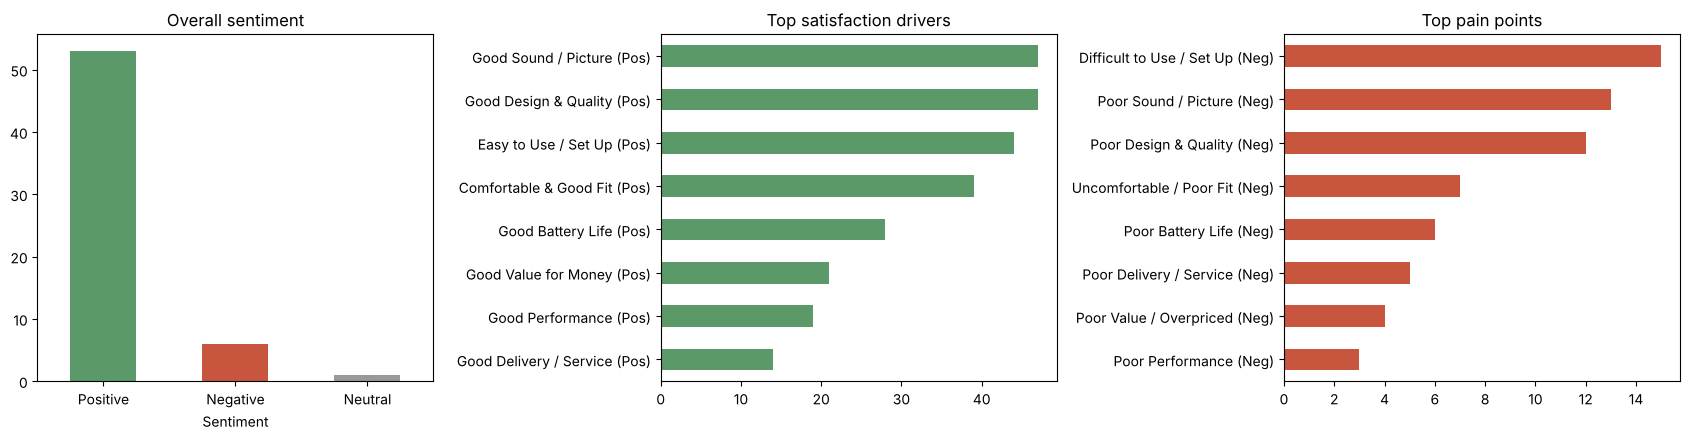

average rating: 4.53  (n=58)


In [12]:
from collections import Counter
import matplotlib.pyplot as plt
tag_counts = Counter(t for lst in df['Category Tags'] for t in lst)
pos = pd.Series({k: v for k, v in tag_counts.items() if k.endswith('(Pos)')}).sort_values(ascending=False)
neg = pd.Series({k: v for k, v in tag_counts.items() if k.endswith('(Neg)')}).sort_values(ascending=False)
print('SATISFACTION DRIVERS\n', pos.head(8), '\n\nPAIN POINTS\n', neg.head(8))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
df['Sentiment'].value_counts().plot.bar(ax=ax[0], color=['#5b9a68', '#c8553d', '#999999'][:df['Sentiment'].nunique()], rot=0); ax[0].set_title('Overall sentiment')
pos.head(8).sort_values().plot.barh(ax=ax[1], color='#5b9a68'); ax[1].set_title('Top satisfaction drivers')
neg.head(8).sort_values().plot.barh(ax=ax[2], color='#c8553d'); ax[2].set_title('Top pain points')
plt.tight_layout(); plt.savefig('task1_sentiment_summary.png', dpi=130); plt.show()
print(f"average rating: {df['Star Rating'].mean():.2f}  (n={df['Star Rating'].notna().sum()})")

In [13]:
# a few real review lines per theme, to quote in the report
for label, d in [('POSITIVE', df[df.Sentiment == 'Positive']), ('NEGATIVE', df[df.Sentiment == 'Negative'])]:
    print('\n==', label)
    for _, r in d.sort_values('Sentiment Score', ascending=(label == 'NEGATIVE')).head(4).iterrows():
        print(f"  [{r['Star Rating']}*] {r['Review Title']} :: {r['Review Body'][:160]}")


== POSITIVE
  [5.0*] Very happy to say :: I'm very happy with my latest Sony WH-1000XM5 ... the sound it's brilliant, very good quality product, very well made, I definitely recommend them.
  [5.0*] Great Headphones :: Brought these headphones for my birthday, wonderful light, love the colour. Sound quality is great and lots of features like Alexa & Google Assistant and 2 poin
  [5.0*] XM5 are awesome!!! :: Honestly transparency not clear like the Apple AirPod max but in my opinion the XM5 are a better all around built headphones.
  [5.0*] Loving it! Features are amazing! :: Absolutely loving this headset! Sounds amazing, using the app I connect to my computer and phone simultaneously and have seemless use between the 2, taking phon

== NEGATIVE
  [1.0*] Very uncomfortable :: I own the XM3 and now the XM4 I came from the XM3 to the XM5. I had the XM5 on my head for one hour and the impression made on my head is as shown on the photos
  [1.0*] DO NOT BUY THESE HEADPHONES :: I've owned 

## 6. Export

In [14]:
out = df.copy()
out['Category Tags'] = out['Category Tags'].map(lambda l: str(l))
out = out[['Primary Key', 'Review Title', 'Review Body', 'Date', 'Star Rating', 'Source Platform', 'Reviewer Name',
           'Sentiment', 'Sentiment Score', 'Sentiment (text only)', 'Text Score', 'Category Tags']]
out.to_csv('bestbuy_reviews_sentiment.csv', index=False, encoding='utf-8')
out.to_excel('bestbuy_reviews_sentiment.xlsx', index=False)
print(out.shape)

(60, 12)
